# A/B Test Readout: Should Cookie Cats Move Its First Gate from Level 30 to Level 40?

**Context.** *Cookie Cats* is a mobile puzzle game. At certain levels players hit a **gate**: they must wait or pay to continue.
The product team tested moving the first gate from level 30 (control, `gate_30`) to level 40 (treatment, `gate_40`),
expecting a later gate to keep new players engaged longer.

**Data.** 90,189 players randomly assigned at install (DataCamp / Tactile Entertainment): rounds played in the first 14 days,
and whether they came back 1 day and 7 days after installing.

**Metrics decided before looking at results**

| Role | Metric | Why |
|---|---|---|
| Primary | 7-day retention | Long-term engagement is what drives in-app purchases and ad revenue |
| Secondary | 1-day retention | Early signal of the first-session experience |
| Guardrail | Rounds played (14 days) | Moving the gate should not reduce how much people play |

**Decision rule.** Ship `gate_40` only if 7-day retention is not significantly worse (α = 0.05) and the guardrail holds.

In [1]:
import sys

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from scipy import stats

sys.path.append("../src")
from ab_stats import bootstrap_diff, mde_two_proportion, sample_size_two_proportion, srm_test, two_proportion_test
from style import C, apply_style, save

apply_style()
GROUP_COLORS = {"gate_30": C["blue"], "gate_40": C["orange"]}

## 1. Data checks

In [2]:
df = pd.read_csv("../data/raw/cookie_cats.csv")
print(f"Players: {len(df):,} | unique ids: {df.userid.nunique():,} | missing values: {df.isna().sum().sum()}")
df["sum_gamerounds"].describe()

Players: 90,189 | unique ids: 90,189 | missing values: 0


count    90189.000000
mean        51.872457
std        195.050858
min          0.000000
25%          5.000000
50%         16.000000
75%         51.000000
max      49854.000000
Name: sum_gamerounds, dtype: float64

One player logged **49,854 rounds** in 14 days (about 2.5 rounds a minute, non-stop). That is a bot or a logging error, so it
is removed. Retention results are unchanged either way; rounds-played averages are distorted by it.

In [3]:
outlier = df["sum_gamerounds"].idxmax()
print(df.loc[outlier].to_dict())
df = df.drop(index=outlier)
counts = df["version"].value_counts()
counts

{'userid': 6390605, 'version': 'gate_30', 'sum_gamerounds': 49854, 'retention_1': False, 'retention_7': True}


version
gate_40    45489
gate_30    44699
Name: count, dtype: int64

### Sample-ratio-mismatch (SRM) check
Players should be split 50/50. A significant imbalance can mean the assignment or logging is broken, which would bias every result.

In [4]:
srm = srm_test(counts["gate_30"], counts["gate_40"])
print(f"gate_30 share: {srm['control_share']:.2%} | chi-square = {srm['chi2']:.2f} | p = {srm['p_value']:.4f}")

gate_30 share: 49.56% | chi-square = 6.92 | p = 0.0085


**Flag:** p ≈ 0.009, so the 49.6 / 50.4 split is unlikely to be chance. The imbalance is small (about 400 players), but in a real
readout I would ask engineering to confirm how assignment is logged before treating the result as final. The analysis continues
with that caveat noted.

## 2. Results

In [5]:
summary = df.groupby("version").agg(
    players=("userid", "size"),
    retention_1=("retention_1", "mean"),
    retention_7=("retention_7", "mean"),
    mean_rounds=("sum_gamerounds", "mean"),
    median_rounds=("sum_gamerounds", "median"),
)
summary.style.format({"players": "{:,}", "retention_1": "{:.2%}", "retention_7": "{:.2%}", "mean_rounds": "{:.1f}", "median_rounds": "{:.0f}"})

,players,retention_1,retention_7,mean_rounds,median_rounds
version,,,,,
gate_30,"44,699",44.82%,19.02%,51.3,17
gate_40,"45,489",44.23%,18.20%,51.3,16


In [6]:
results = {}
for metric in ["retention_7", "retention_1"]:
    c = df.loc[df.version == "gate_30", metric]
    t = df.loc[df.version == "gate_40", metric]
    results[metric] = two_proportion_test(c.sum(), len(c), t.sum(), len(t))
res = pd.DataFrame(results).T
res.style.format({"control": "{:.2%}", "treatment": "{:.2%}", "diff": "{:+.2%}", "rel_lift": "{:+.1%}",
                  "ci_low": "{:+.2%}", "ci_high": "{:+.2%}", "z": "{:.2f}", "p_value": "{:.4f}"})

,control,treatment,diff,rel_lift,ci_low,ci_high,z,p_value
retention_7,19.02%,18.20%,-0.82%,-4.3%,-1.33%,-0.31%,-3.16,0.0016
retention_1,44.82%,44.23%,-0.59%,-1.3%,-1.24%,+0.06%,-1.79,0.0739


In [7]:
# Guardrail: rounds played is heavily skewed, so use a non-parametric test
r30 = df.loc[df.version == "gate_30", "sum_gamerounds"]
r40 = df.loc[df.version == "gate_40", "sum_gamerounds"]
mw = stats.mannwhitneyu(r30, r40, alternative="two-sided")
print(f"Rounds played: median {r30.median():.0f} vs {r40.median():.0f} | Mann-Whitney p = {mw.pvalue:.3f}")

Rounds played: median 17 vs 16 | Mann-Whitney p = 0.051


### Bootstrap view
How sure are we that the level-30 gate retains more players? A bootstrap gives the full distribution of the difference.

retention_1: gate_40 worse in 9,656 of 10,000 resamples (96.56%)
retention_7: gate_40 worse in 9,996 of 10,000 resamples (99.96%)


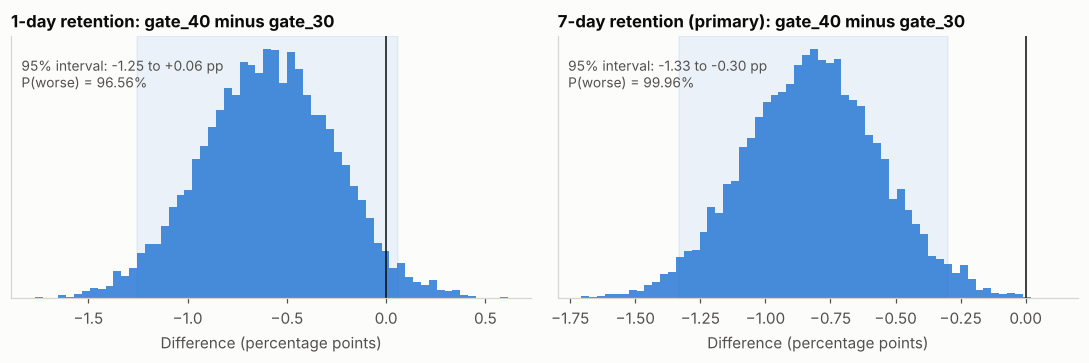

In [8]:
boot = {}
for metric in ["retention_1", "retention_7"]:
    c = df.loc[df.version == "gate_30", metric].astype(int).to_numpy()
    t = df.loc[df.version == "gate_40", metric].astype(int).to_numpy()
    boot[metric] = bootstrap_diff(c, t, n_boot=10_000)
    print(f"{metric}: gate_40 worse in {(boot[metric] < 0).sum():,} of {len(boot[metric]):,} resamples ({(boot[metric] < 0).mean():.2%})")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=False)
for ax, (metric, label) in zip(axes, [("retention_1", "1-day retention"), ("retention_7", "7-day retention (primary)")]):
    d = boot[metric] * 100
    ax.hist(d, bins=60, color=C["blue"], alpha=0.85)
    ax.axvline(0, color=C["ink"], lw=1)
    lo, hi = np.percentile(d, [2.5, 97.5])
    ax.axvspan(lo, hi, color=C["blue"], alpha=0.08)
    ax.set_title(f"{label}: gate_40 minus gate_30", fontsize=11)
    ax.set_xlabel("Difference (percentage points)")
    ax.text(0.02, 0.92, f"95% interval: {lo:+.2f} to {hi:+.2f} pp\nP(worse) = {(d < 0).mean():.2%}", transform=ax.transAxes,
            fontsize=9, color=C["ink2"], va="top")
    ax.set_yticks([])
save(fig, "01_bootstrap_retention_difference")
plt.show()

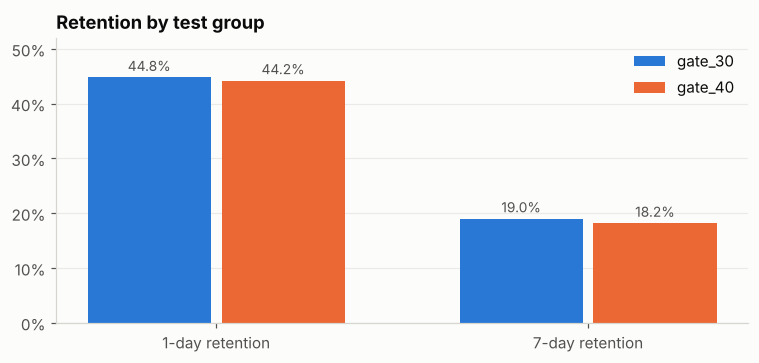

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.4))
x = np.arange(2)
w = 0.36
for i, g in enumerate(["gate_30", "gate_40"]):
    vals = [summary.loc[g, "retention_1"], summary.loc[g, "retention_7"]]
    bars = ax.bar(x + (i - 0.5) * w, vals, w * 0.92, color=GROUP_COLORS[g], label=g)
    ax.bar_label(bars, labels=[f"{v:.1%}" for v in vals], padding=2, fontsize=9, color=C["ink2"])
ax.set_xticks(x, ["1-day retention", "7-day retention"])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylim(0, 0.52)
ax.legend()
ax.set_title("Retention by test group")
save(fig, "02_retention_by_group")
plt.show()

## 3. Was the test big enough?

In [10]:
n_per_group = counts.min()
p7 = summary.loc["gate_30", "retention_7"]
mde7 = mde_two_proportion(p7, n_per_group)
print(f"With ~{n_per_group:,} players per group, the smallest 7-day retention change detectable at 80% power is "
      f"{mde7:.2%} (absolute).")
print(f"Observed change: {res.loc['retention_7','diff']:+.2%} -> larger than the MDE, so the test was adequately powered.")
p1 = summary.loc["gate_30", "retention_1"]
print(f"For 1-day retention the MDE is {mde_two_proportion(p1, n_per_group):.2%}; the observed {res.loc['retention_1','diff']:+.2%} is below it,")
print(f"so detecting it reliably would need ~{sample_size_two_proportion(p1, res.loc['retention_1','diff']):,} players per group.")

With ~44,699 players per group, the smallest 7-day retention change detectable at 80% power is 0.74% (absolute).
Observed change: -0.82% -> larger than the MDE, so the test was adequately powered.
For 1-day retention the MDE is 0.93%; the observed -0.59% is below it,
so detecting it reliably would need ~110,812 players per group.


### A pitfall avoided: segmenting by rounds played
It is tempting to compare only players who "reached level 30". Rounds played happens **after** assignment and is itself affected
by where the gate is, so splitting on it breaks randomisation and can show effects that are not there. All comparisons above use
the full randomised groups (intention-to-treat).

## 4. Business impact and decision

In [11]:
d7 = res.loc["retention_7", "diff"]
per_100k = -d7 * 100_000
print(f"Moving the gate to level 40 would mean ~{per_100k:,.0f} fewer players still active on day 7 for every 100,000 installs "
      f"({res.loc['retention_7','rel_lift']:+.1%} relative).")

Moving the gate to level 40 would mean ~818 fewer players still active on day 7 for every 100,000 installs (-4.3% relative).


**Decision: keep the gate at level 30.**

- 7-day retention (primary) is **0.82 pp lower** with the gate at 40 (19.02% → 18.20%, p ≈ 0.002; gate_40 was worse in 99.96% of 10,000 bootstrap resamples).
- 1-day retention is 0.59 pp lower, but this is not statistically significant.
- Rounds played show no significant difference (mean 51.3 in both groups, Mann-Whitney p ≈ 0.05), so the guardrail holds; the cost shows up in returning players, not in how much they play.
- **Why it might happen (hypothesis for the next test):** the gate forces a break. A break at level 30 may make the game feel
  more rewarding when players come back (hedonic adaptation), while a gate at 40 lets players burn out first.

**Next steps**
1. Confirm the SRM cause with engineering before closing the experiment.
2. Test the opposite direction (gate at level 25), and gate *length* rather than position.
3. Add revenue per user as a secondary metric next time, since retention is only a proxy for revenue.

In [12]:
print(f"""
Summary
- Players analysed: {len(df):,} (1 bot-like outlier removed); SRM p = {srm['p_value']:.3f} (flagged)
- 7-day retention: {res.loc['retention_7','control']:.2%} (gate_30) vs {res.loc['retention_7','treatment']:.2%} (gate_40),
  diff {res.loc['retention_7','diff']*100:+.2f} pp, 95% CI [{res.loc['retention_7','ci_low']*100:+.2f}, {res.loc['retention_7','ci_high']*100:+.2f}] pp, p = {res.loc['retention_7','p_value']:.4f}
- 1-day retention: diff {res.loc['retention_1','diff']*100:+.2f} pp, p = {res.loc['retention_1','p_value']:.3f}
- Bootstrap: gate_40 worse on 7-day retention in {(boot['retention_7'] < 0).mean():.2%} of 10,000 resamples
- MDE (7-day, 80% power) = {mde7*100:.2f} pp; impact = {per_100k:,.0f} fewer day-7 players per 100k installs
""")


Summary
- Players analysed: 90,188 (1 bot-like outlier removed); SRM p = 0.009 (flagged)
- 7-day retention: 19.02% (gate_30) vs 18.20% (gate_40),
  diff -0.82 pp, 95% CI [-1.33, -0.31] pp, p = 0.0016
- 1-day retention: diff -0.59 pp, p = 0.074
- Bootstrap: gate_40 worse on 7-day retention in 99.96% of 10,000 resamples
- MDE (7-day, 80% power) = 0.74 pp; impact = 818 fewer day-7 players per 100k installs

